In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import joblib
import pymongo
import os

from pymongo import MongoClient
#load dataset
df =pd.read_csv('uncleaned_solar_voltage_dataset.csv')

In [79]:
# import sys
# !{sys.executable} -m pip install pymongo

In [80]:
MONGO_URI = os.getenv("MONGO_URI")

client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=5000)

# Test connection
client.admin.command("ping")
print("Connected to MongoDB successfully!")

# Select database
db = client["solar_energy_db"]

# Explicitly create collections if they do not exist
if "cleaned_solar_data" not in db.list_collection_names():
    db.create_collection("cleaned_solar_data")

if "trained_models" not in db.list_collection_names():
    db.create_collection("trained_models")

cleaned_collection = db["cleaned_solar_data"]
model_collection = db["trained_models"]

# print("Database:", db.name)
# print("Collections:", db.list_collection_names())

Connected to MongoDB successfully!


In [81]:
# Display basic information
print("Dataset shape:", df.shape)

Dataset shape: (506, 4)


In [82]:
print("\nFirst 5 rows:")
display(df.head(5))


First 5 rows:


,ID,Light_Intensity_Lux,Temperature_C,Voltage_V
0,SOL0174,93604.4,43.0,7.310
1,SOL0275,68071.5,15.2,5.641
2,SOL0492,64794.8,45.0,5.716
3,SOL0073,85340.3,34.3,6.731
4,SOL0453,70957.8,24.8,5.911


In [83]:
print("\nData types:")
print(df.dtypes)


Data types:
ID                         str
Light_Intensity_Lux    float64
Temperature_C          float64
Voltage_V              float64
dtype: object


In [84]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   506 non-null    str    
 1   Light_Intensity_Lux  483 non-null    float64
 2   Temperature_C        487 non-null    float64
 3   Voltage_V            486 non-null    float64
dtypes: float64(3), str(1)
memory usage: 15.9 KB


In [85]:
print("\nSummary statistics:")
display(df.describe(include="all"))


Summary statistics:


,ID,Light_Intensity_Lux,Temperature_C,Voltage_V
count,506,483.000000,487.000000,486.000000
unique,500,NaN,NaN,NaN
top,SOL0044,NaN,NaN,NaN
freq,2,NaN,NaN,NaN
mean,NaN,50066.882402,35.888090,4.644156
std,NaN,30354.479200,15.036567,2.117508
min,NaN,-500.000000,15.000000,-3.500000
25%,NaN,23260.550000,24.800000,3.059500
50%,NaN,50633.000000,35.000000,4.660500
75%,NaN,75983.000000,45.900000,5.912500


In [86]:
#Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
ID                      0
Light_Intensity_Lux    23
Temperature_C          19
Voltage_V              20
dtype: int64


In [87]:
#Check duplicate records
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 6


In [88]:
#Remove duplicates:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (500, 4)


In [89]:

#Check impossible values
numeric_columns = [
    "Light_Intensity_Lux",
    "Temperature_C",
    "Voltage_V"
]

for col in numeric_columns:
    print(f"\n{col}")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())


Light_Intensity_Lux
Minimum: -500.0
Maximum: 250000.0

Temperature_C
Minimum: 15.0
Maximum: 180.0

Voltage_V
Minimum: -3.5
Maximum: 25.0


In [90]:
#Check negative values and all columns has number values
for col in numeric_columns:
    negative_count = (pd.to_numeric(df[col], errors="coerce") < 0).sum()
    print(f"{col}: {negative_count} negative values")

Light_Intensity_Lux: 4 negative values
Temperature_C: 0 negative values
Voltage_V: 2 negative values


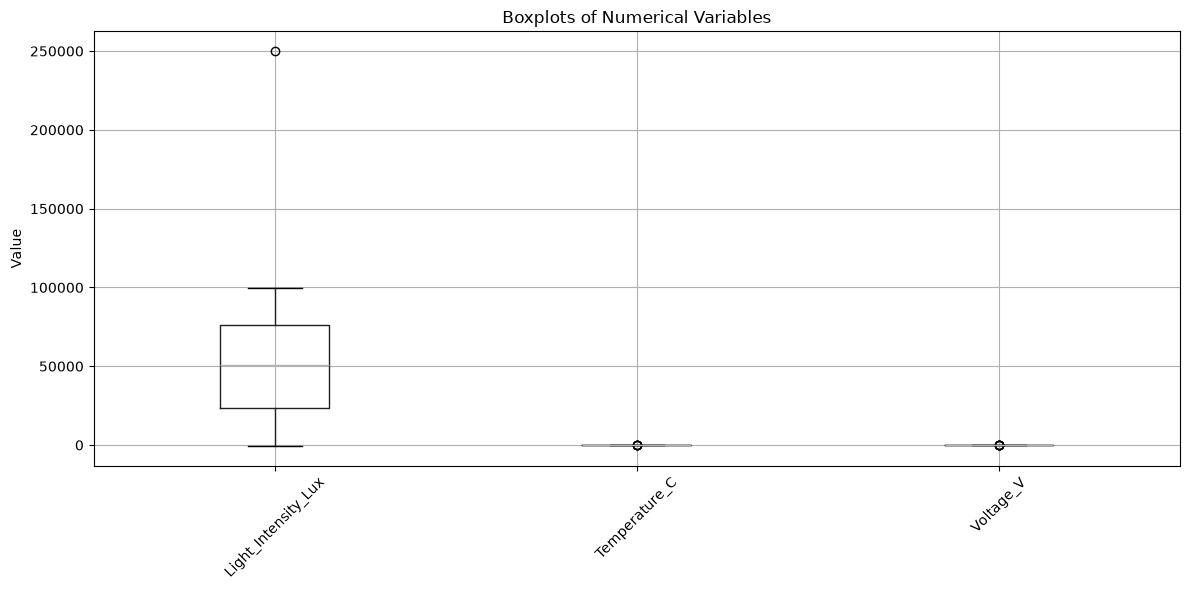

In [91]:
#boxplots visualization
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

df[numeric_columns].boxplot()

plt.title("Boxplots of Numerical Variables")
plt.xticks(rotation=45)
plt.ylabel("Value")
plt.tight_layout()
plt.show()

In [92]:
#Detect outliers using the IQR method
outlier_counts = {}

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_counts[col] = len(outliers)

    print(f"{col}: {len(outliers)} outliers")

print("\nOutlier summary:")
print(pd.Series(outlier_counts))

Light_Intensity_Lux: 1 outliers
Temperature_C: 4 outliers
Voltage_V: 5 outliers

Outlier summary:
Light_Intensity_Lux    1
Temperature_C          4
Voltage_V              5
dtype: int64


In [93]:
 #Handle outliers using the IQR capping method (Winsorization)

df_clean = df.copy()

for col in numeric_columns:
    # Calculate quartiles
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    # Calculate Interquartile Range
    IQR = Q3 - Q1

    # Calculate lower and upper boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    #  outliers instead of deleting rows
    df_clean[col] = df_clean[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Rows retained:", len(df_clean))


Original shape: (500, 4)
Cleaned shape: (500, 4)
Rows retained: 500


In [94]:
# Check missing values after capping
print(df_clean.isnull().sum())

# Check total missing values
print("Total missing values:", df_clean.isnull().sum().sum())

ID                      0
Light_Intensity_Lux    23
Temperature_C          19
Voltage_V              20
dtype: int64
Total missing values: 62


In [95]:


# Fill missing values after outlier capping
df_clean = df_clean.copy()

# Measurement columns
numeric_columns = [
    "Light_Intensity_Lux",
    "Temperature_C",
    "Voltage_V"
]

# Fill missing values using each column's median
for col in numeric_columns:
    median_value = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_value)

# Verify the results
print("Missing values after imputation:")
print(df_clean[numeric_columns].isnull().sum())

print("\nTotal missing values:",
      df_clean[numeric_columns].isnull().sum().sum())

print("\nOriginal dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)


Missing values after imputation:
Light_Intensity_Lux    0
Temperature_C          0
Voltage_V              0
dtype: int64

Total missing values: 0

Original dataset shape: (500, 4)
Cleaned dataset shape: (500, 4)


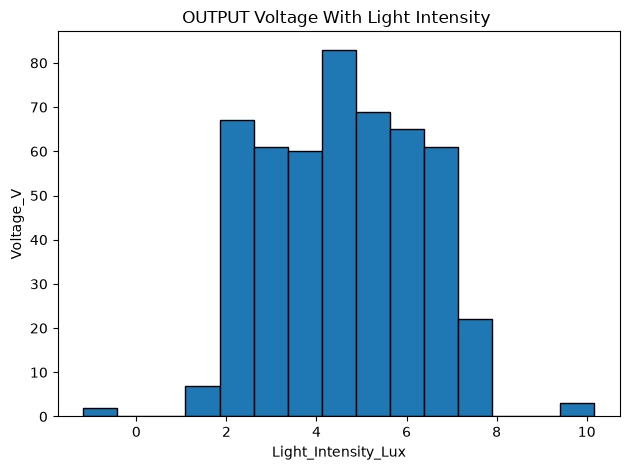

In [96]:
plt.hist(
    df_clean["Voltage_V"],
    bins=15,
    edgecolor="black"
)

plt.title("OUTPUT Voltage With Light Intensity ")
plt.xlabel("Light_Intensity_Lux")
plt.ylabel("Voltage_V")

plt.tight_layout()
plt.show()

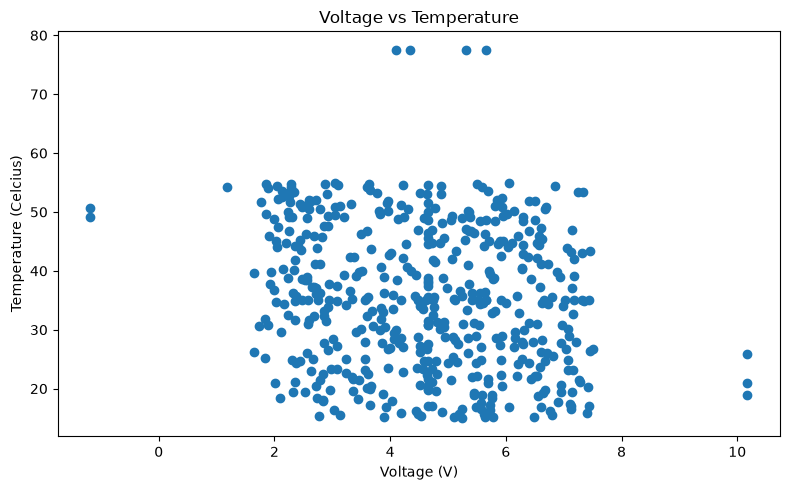

In [97]:
#Visualisation — Voltage vs Temperature
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Voltage_V"],
    df_clean["Temperature_C"]
)

plt.title("Voltage vs Temperature")
plt.xlabel("Voltage (V)")
plt.ylabel("Temperature (Celcius)")

plt.tight_layout()
plt.show()

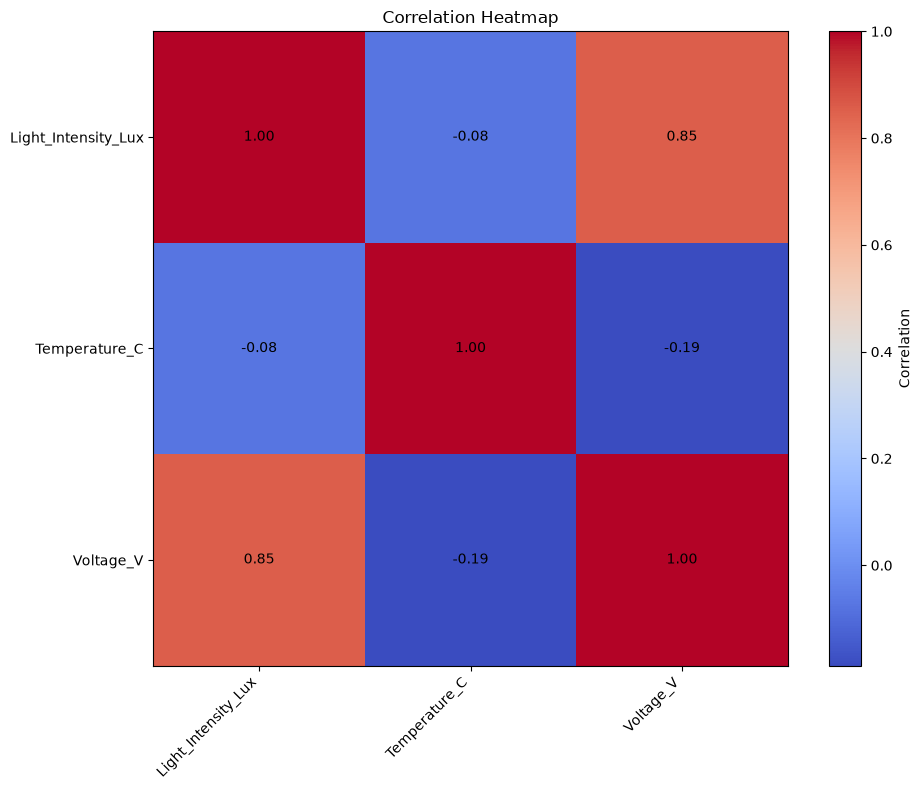

In [98]:
#Visualisation — Correlation heatmap
correlation = df_clean[numeric_columns].corr()

plt.figure(figsize=(10, 8))

plt.imshow(
    correlation,
    cmap="coolwarm",
    interpolation="nearest"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Heatmap")

# Add correlation values
for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j,
            i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [99]:
#Save the cleaned dataset
df_clean.to_csv(
    "cleaned_solar_voltage_dataset.csv",
    index=False
)

In [100]:
#save the cleaned data to mongodb
records = (
    df_clean.astype(object)
    .where(pd.notna(df_clean), None)
    .to_dict(orient="records")
)

# Replace the collection contents with the current cleaned dataset
cleaned_collection.delete_many({})

if records:
    result = cleaned_collection.insert_many(records)
    print(f"Saved {len(result.inserted_ids)} records to MongoDB.")
else:
    print("No records to save.")

print("Documents in MongoDB:", cleaned_collection.count_documents({}))


Saved 500 records to MongoDB.
Documents in MongoDB: 500


In [101]:
# Load cleaned dataset
df = pd.read_csv("cleaned_solar_voltage_dataset.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df.isnull().sum())

Dataset shape: (500, 4)
        ID  Light_Intensity_Lux  Temperature_C  Voltage_V
0  SOL0174              93604.4           43.0      7.310
1  SOL0275              68071.5           15.2      5.641
2  SOL0492              64794.8           45.0      5.716
3  SOL0073              85340.3           34.3      6.731
4  SOL0453              70957.8           24.8      5.911
ID                     0
Light_Intensity_Lux    0
Temperature_C          0
Voltage_V              0
dtype: int64


In [102]:
#Select features and target
# For this project:
#Input features (X): light intensity and temperature.
# Target (y): voltage.
X = df[["Light_Intensity_Lux", "Temperature_C"]]
y = df["Voltage_V"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (500, 2)
Target shape: (500,)


In [103]:
#Split the dataset
#We will use 80% of the data for training and 20% for testing.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 400
Testing records: 100


In [104]:
#Train the Multiple Linear Regression 

model = LinearRegression()
model.fit(X_train, y_train)

print("Model training completed!")
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Model training completed!
Intercept: 2.6452606026458607
Coefficients: [ 4.97648168e-05 -1.46299602e-02]


In [105]:
#Evaluate the model
#Use the test dataset, which the model did not see during training
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print(f"MAE:  {mae:.4f} V")
print(f"RMSE: {rmse:.4f} V")
print(f"R² Score: {r2:.4f}")

Model Evaluation Results
-------------------------
MAE:  0.4478 V
RMSE: 0.7794 V
R² Score: 0.7644


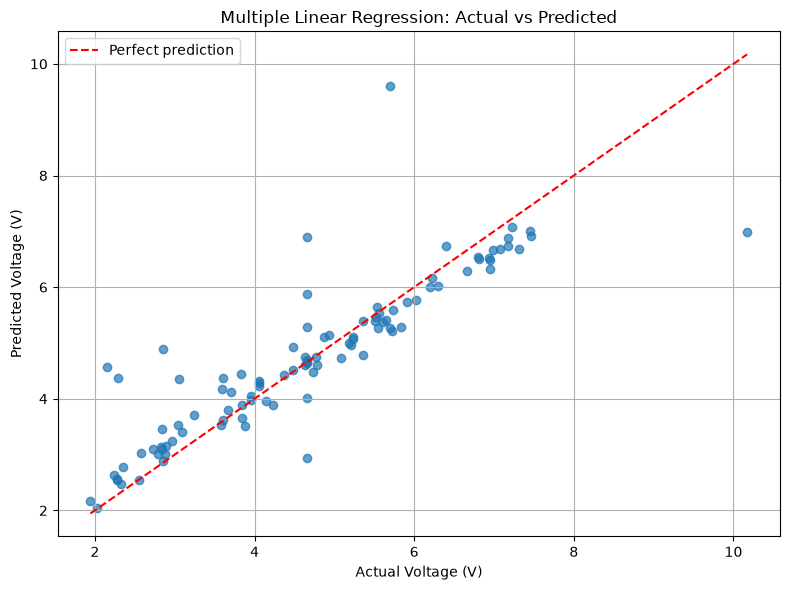

In [106]:
#Visualize actual vs. predicted voltage
#This plot helps you see how closely the predictions match the actual measurements.
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Voltage (V)")
plt.ylabel("Predicted Voltage (V)")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [107]:

joblib.dump(model, "solar_voltage_model.sav")

print("Trained model saved successfully!")

Trained model saved successfully!


In [108]:

from gridfs import GridFS
from datetime import datetime, timezone

# The model file created by your notebook
model_path = "solar_voltage_model.sav"

if not os.path.exists(model_path):
    raise FileNotFoundError(
        f"{model_path} not found. Run your model training cell first."
    )

# Upload the model file to MongoDB GridFS
fs = GridFS(db, collection="model_files")

with open(model_path, "rb") as model_file:
    model_file_id = fs.put(
        model_file,
        filename=model_path,
        contentType="application/octet-stream"
    )

# Save model information and evaluation results
model_document = {
    "model_name": "Multiple Linear Regression",
    "features": [
        "Light_Intensity_Lux",
        "Temperature_C"
    ],
    "target": "Voltage_V",
    "intercept": float(model.intercept_),
    "coefficients": {
        "Light_Intensity_Lux": float(model.coef_[0]),
        "Temperature_C": float(model.coef_[1])
    },
    "evaluation_metrics": {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "R2": float(r2)
    },
    "model_file_id": model_file_id,
    "created_at": datetime.now(timezone.utc)
}

result = model_collection.insert_one(model_document)

print("Model saved successfully!")
print("MongoDB model document ID:", result.inserted_id)
print("Model file ID:", model_file_id)
print("Evaluation metrics:", model_document["evaluation_metrics"])


Model saved successfully!
MongoDB model document ID: 6ad7c7572edefbf920681159
Model file ID: 6ad7c7572edefbf920681157
Evaluation metrics: {'MAE': 0.4477851150034147, 'RMSE': 0.7794212265562213, 'R2': 0.7643689307901087}


In [109]:

print("First 5 cleaned records:")
for record in cleaned_collection.find().limit(30):
    print(record)

print("\nLatest saved model:")
saved_model = model_collection.find_one(
    sort=[("created_at", -1)]
)

if saved_model:
    print("Model:", saved_model["model_name"])
    print("Features:", saved_model["features"])
    print("Coefficients:", saved_model["coefficients"])
    print("Metrics:", saved_model["evaluation_metrics"])
else:
    print("No model metadata found.")


First 5 cleaned records:
{'_id': ObjectId('6ad7c7562edefbf920680f63'), 'ID': 'SOL0174', 'Light_Intensity_Lux': 93604.4, 'Temperature_C': 43.0, 'Voltage_V': 7.31}
{'_id': ObjectId('6ad7c7562edefbf920680f64'), 'ID': 'SOL0275', 'Light_Intensity_Lux': 68071.5, 'Temperature_C': 15.2, 'Voltage_V': 5.641}
{'_id': ObjectId('6ad7c7562edefbf920680f65'), 'ID': 'SOL0492', 'Light_Intensity_Lux': 64794.8, 'Temperature_C': 45.0, 'Voltage_V': 5.716}
{'_id': ObjectId('6ad7c7562edefbf920680f66'), 'ID': 'SOL0073', 'Light_Intensity_Lux': 85340.3, 'Temperature_C': 34.3, 'Voltage_V': 6.731}
{'_id': ObjectId('6ad7c7562edefbf920680f67'), 'ID': 'SOL0453', 'Light_Intensity_Lux': 70957.8, 'Temperature_C': 24.8, 'Voltage_V': 5.911}
{'_id': ObjectId('6ad7c7562edefbf920680f68'), 'ID': 'SOL0077', 'Light_Intensity_Lux': 29359.4, 'Temperature_C': 51.4, 'Voltage_V': 3.321}
{'_id': ObjectId('6ad7c7562edefbf920680f69'), 'ID': 'SOL0317', 'Light_Intensity_Lux': 37946.4, 'Temperature_C': 50.2, 'Voltage_V': 3.96}
{'_id': Obj